# PaySim: week-three data audit and feature feasibility
**Shuveccha Barua | Advanced Topics in AI**

**Project question:** Do historical graph features improve fraud detection compared with transaction-only features?
This week I have checked the data and whether useful account history exists. It ends with a preliminary feature plan
and a list of questions for my supervisor; model training and performance comparisons are later work.

Transactions form directed edges from senders to receivers. Accounts are nodes. In PaySim, `step` represents
one simulation hour. Ordering within an hour is unavailable, so only **strictly earlier steps** count as history.



## 1. Setup, data location and requirements

DuckDB processes the large transaction file; pandas holds the smaller result tables.
The helper code saves results and quotes file paths safely.

**Requirements:** Python 3.10+, `duckdb`, `pandas`, `numpy`, `matplotlib` (and `ipython`/Jupyter to run the notebook).

**Data location:** set the environment variable `PAYSIM_CSV` to the PaySim CSV, or edit `DATA_PATH` in the paths cell
. A file picker is only an optional fallback when
the path does not exist.

In [21]:
pip install -q duckdb pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [22]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import os
import platform
import uuid
import duckdb
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.2})

def sql_text(value):
    """Quote a SQL string literal, including paths that contain apostrophes."""
    return "'" + str(value).replace("'", "''") + "'"

def sql_name(value):
    """Quote a SQL column identifier."""
    return '"' + str(value).replace('"', '""') + '"'

def run_sql(label, sql, fetch=True):
    """Run an audit query; only small aggregate results are fetched into pandas."""
    result = con.execute(sql)
    return result.df() if fetch else None

def save_table(table, name):
    table.to_csv(RESULTS_DIR / f"{name}.csv", index=False)

def save_figure(name):
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

print("Python", platform.python_version(), "| DuckDB", duckdb.__version__, "| pandas", pd.__version__)

Python 3.13.7 | DuckDB 1.5.5 | pandas 2.3.3


In [ ]:
# Project paths and run settings.
PROJECT_ROOT = Path.cwd().resolve()

# Edit this path or set the PAYSIM_CSV environment variable (relative paths are relative to this notebook).
DATA_PATH = Path(os.environ.get("PAYSIM_CSV", "C://Users//ASUS//Desktop//Davide//Project2//paysim dataset.csv")).expanduser()
USE_FILE_PICKER_FALLBACK = True   # only used when DATA_PATH does not exist

if not DATA_PATH.is_file() and USE_FILE_PICKER_FALLBACK:
    print(f"CSV not found at {DATA_PATH}. Trying a file picker as a fallback.")
    selected = ""
    try:
        import tkinter as tk
        from tkinter import filedialog
        root = tk.Tk()
        root.withdraw()
        root.attributes("-topmost", True)
        selected = filedialog.askopenfilename(
            title="Select the PaySim CSV file",
            filetypes=[("CSV files", "*.csv"), ("All files", "*.*")],
        )
        root.destroy()
    except Exception:
        selected = ""
    if not selected:
        try:
            selected = input("Paste the full path to the PaySim CSV (leave blank to cancel): ").strip().strip('"')
        except Exception:
            selected = ""
    if selected:
        DATA_PATH = Path(selected).expanduser()

if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"PaySim CSV not found: {DATA_PATH}. Set PAYSIM_CSV or edit DATA_PATH in this cell."
    )
DATA_PATH = DATA_PATH.resolve()
print("Using CSV:", DATA_PATH.name)

# MAX_STEP=None runs the complete dataset.
MAX_STEP = None
WINDOWS = (6, 24, 48)
MEMORY_LIMIT = "4GB"
THREADS = 4
FORCE_REBUILD_CACHE = False

CSV not found at data\raw\paysim.csv. Trying a file picker as a fallback.
Using CSV: paysim dataset.csv


In [24]:
# Check the file 
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"CSV not found: {DATA_PATH}. Edit DATA_PATH in the paths cell."
    )

if MAX_STEP is not None and (
    not isinstance(MAX_STEP, int)
    or isinstance(MAX_STEP, bool)
    or MAX_STEP < 0
):
    raise ValueError("MAX_STEP must be None or a nonnegative integer.")

if any(not isinstance(w, int) or w <= 0 for w in WINDOWS) or 24 not in WINDOWS:
    raise ValueError("Use positive integer windows including 24 hours.")

if not isinstance(THREADS, int) or THREADS < 1:
    raise ValueError("THREADS must be a positive integer.")


# Create a separate results folder
mode = "full" if MAX_STEP is None else f"through_step_{MAX_STEP}"

run_id = (
    datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    + "_"
    + uuid.uuid4().hex[:6]
)

RESULTS_DIR = PROJECT_ROOT / "results" / f"paysim_week3_{mode}_{run_id}"
FIGURES_DIR = RESULTS_DIR / "figures"
CACHE_DIR = PROJECT_ROOT / "data" / "interim" / "paysim_audit_cache"
TEMP_DIR = RESULTS_DIR / "duckdb_tmp"

for directory in [FIGURES_DIR, CACHE_DIR, TEMP_DIR]:
    directory.mkdir(parents=True, exist_ok=True)


# Open and configuration of DuckDB
if "con" in globals():
    con.close()

con = duckdb.connect()
con.execute(f"SET memory_limit = {sql_text(MEMORY_LIMIT)}")
con.execute(f"SET threads = {THREADS}")
con.execute(f"SET temp_directory = {sql_text(TEMP_DIR.as_posix())}")
con.execute("SET preserve_insertion_order = false")


# Confirm the selected locations
print("Source file:", DATA_PATH.name)
print("Results folder:", RESULTS_DIR.relative_to(PROJECT_ROOT))

if MAX_STEP is not None:
    print(
        "PARTIAL TIME PREFIX: use for code checks, "
        "not full-dataset conclusions."
    )

Source file: paysim dataset.csv
Results folder: results\paysim_week3_full_20261005T114051Z_4fbc7c


## 2. Load and validate the data

The source file is checked before analysis: required columns, missing values in every column, valid whole-hour
steps, nonnegative finite amounts, nonblank account IDs and binary labels. Invalid core values stop the run;
records are not silently removed or filled. Missing optional balance fields are reported without using them as features.

A SHA-256 fingerprint identifies the CSV and its reusable Parquet cache. Values remain text until validation,
so an invalid label such as `0.5` cannot be rounded into a valid one. Detailed checks are saved as CSVs.
The overview below describes the selected data; `MAX_STEP` is only an optional debugging time limit.

In [25]:
source_stat_before = DATA_PATH.stat()
source_hash = sha256_file(DATA_PATH)
source_stat_after = DATA_PATH.stat()
if (source_stat_before.st_size, source_stat_before.st_mtime_ns) != (source_stat_after.st_size, source_stat_after.st_mtime_ns):
    raise RuntimeError("The CSV changed while hashing. Stop editing it and rerun.")

CACHE_VERSION = "raw_v2"
CACHE_PATH = CACHE_DIR / f"{CACHE_VERSION}_{source_hash}.parquet"
CACHE_META = CACHE_PATH.with_suffix(".json")
expected_cache = {"schema_version": CACHE_VERSION, "source_sha256": source_hash,
                  "source_bytes": source_stat_after.st_size}
cache_ok = False
if CACHE_PATH.is_file() and CACHE_META.is_file() and not FORCE_REBUILD_CACHE:
    try:
        cached_meta = json.loads(CACHE_META.read_text(encoding="utf-8"))
        cache_ok = all(cached_meta.get(k) == v for k, v in expected_cache.items())
    except (ValueError, OSError):
        cache_ok = False

if not cache_ok:
    temporary_cache = CACHE_PATH.with_name(CACHE_PATH.stem + ".building_" + uuid.uuid4().hex + ".parquet")
    try:
        run_sql("CSV to Parquet cache", f"""
            COPY (SELECT * FROM read_csv({sql_text(DATA_PATH.as_posix())},
                header=true, all_varchar=true, ignore_errors=false))
            TO {sql_text(temporary_cache.as_posix())} (FORMAT PARQUET, COMPRESSION ZSTD)
        """, fetch=False)
        after_copy = DATA_PATH.stat()
        if (after_copy.st_size, after_copy.st_mtime_ns) != (source_stat_after.st_size, source_stat_after.st_mtime_ns):
            raise RuntimeError("CSV changed during cache creation; rerun with a stable input file.")
        temporary_cache.replace(CACHE_PATH)
        CACHE_META.write_text(json.dumps(expected_cache, indent=2), encoding="utf-8")
    finally:
        if temporary_cache.exists():
            temporary_cache.unlink()
else:
    print("Reusing cache for matching source SHA-256:", source_hash[:16])

con.execute(f"CREATE OR REPLACE TEMP VIEW raw AS SELECT * FROM read_parquet({sql_text(CACHE_PATH.as_posix())})")
schema = con.execute("DESCRIBE raw").df()
save_table(schema, "source_schema")
CORE = {"step", "type", "amount", "nameOrig", "nameDest", "isFraud"}
STANDARD = CORE | {"oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest", "isFlaggedFraud"}
actual_columns = set(schema["column_name"])
if CORE - actual_columns:
    raise ValueError(f"Required columns missing: {sorted(CORE - actual_columns)}")
HAS_FLAG = "isFlaggedFraud" in actual_columns
if STANDARD - actual_columns:
    print("Absent optional columns:", sorted(STANDARD - actual_columns))

Reusing cache for matching source SHA-256: 16910f90577b0d98


In [26]:
#Missingness and core-value validation
null_expressions = [f"COUNT(*) FILTER (WHERE {sql_name(c)} IS NULL) AS {sql_name(c)}" for c in schema["column_name"]]
nulls = run_sql("All-column missingness", "SELECT " + ", ".join(null_expressions) + " FROM raw")
missingness = nulls.T.reset_index()
missingness.columns = ["column", "missing_count"]
save_table(missingness, "missingness_all_columns")

step_value = 'TRY_CAST(step AS DOUBLE)'
amount_value = 'TRY_CAST(amount AS DOUBLE)'
label_value = 'TRY_CAST(isFraud AS DOUBLE)'
conditions = {
    "invalid_step": f"{step_value} IS NULL OR NOT isfinite({step_value}) OR {step_value} < 0 OR {step_value} > 2147483647 OR {step_value} != floor({step_value})",
    "invalid_amount": f"{amount_value} IS NULL OR NOT isfinite({amount_value}) OR {amount_value} < 0",
    "invalid_fraud_label": f"{label_value} IS NULL OR {label_value} NOT IN (0, 1)",
    "missing_or_blank_type": "type IS NULL OR length(trim(type)) = 0",
    "missing_or_blank_sender": "nameOrig IS NULL OR length(trim(nameOrig)) = 0",
    "missing_or_blank_receiver": "nameDest IS NULL OR length(trim(nameDest)) = 0",
}
if HAS_FLAG:
    conditions["invalid_existing_flag"] = "TRY_CAST(isFlaggedFraud AS DOUBLE) IS NULL OR TRY_CAST(isFlaggedFraud AS DOUBLE) NOT IN (0, 1)"
checks = run_sql("Core validation", "SELECT COUNT(*) AS rows, " + ", ".join(
    f"COUNT(*) FILTER (WHERE {condition}) AS {sql_name(name)}" for name, condition in conditions.items()
) + " FROM raw")
quality = checks.drop(columns="rows").T.reset_index()
quality.columns = ["check", "count"]
save_table(quality, "data_quality")
if int(checks.loc[0, "rows"]) == 0:
    raise ValueError("The source CSV has no transactions.")
if quality["count"].sum() > 0:
    raise ValueError("Invalid core values found. Inspect data_quality.csv; no records were removed or filled.")

flag_selection = ", CAST(TRY_CAST(isFlaggedFraud AS DOUBLE) AS TINYINT) AS isFlaggedFraud" if HAS_FLAG else ""
con.execute(f"""CREATE OR REPLACE TEMP VIEW paysim_all AS
    SELECT CAST(TRY_CAST(step AS DOUBLE) AS INTEGER) AS step, type,
           CAST(amount AS DOUBLE) AS amount, nameOrig, nameDest,
           CAST(TRY_CAST(isFraud AS DOUBLE) AS TINYINT) AS isFraud {flag_selection}
    FROM raw""")
time_filter = "" if MAX_STEP is None else f"WHERE step <= {MAX_STEP}"
con.execute(f"CREATE OR REPLACE TEMP VIEW paysim AS SELECT * FROM paysim_all {time_filter}")
if con.execute("SELECT COUNT(*) FROM paysim").fetchone()[0] == 0:
    raise ValueError("No rows remain in the selected time prefix. Increase MAX_STEP.")


quality_summary = pd.DataFrame([
    ("Rows checked in the full source", int(checks.loc[0, "rows"])),
    ("Missing cells across all source columns", int(missingness["missing_count"].sum())),
    ("Invalid core values", int(quality["count"].sum())),
], columns=["check", "count"])
display(quality_summary)
if missingness["missing_count"].sum() > 0:
    display(missingness[missingness["missing_count"] > 0])
save_table(quality_summary, "quality_summary")

,check,count
0,Rows checked in the full source,6362620
1,Missing cells across all source columns,0
2,Invalid core values,0


In [27]:
#Dataset overview
overview = run_sql("Overview", """
    SELECT COUNT(*) AS transactions, MIN(step) AS first_step, MAX(step) AS last_step,
           COUNT(DISTINCT step) AS observed_steps, SUM(isFraud) AS fraud,
           100.0 * AVG(isFraud) AS fraud_rate_pct,
           COUNT(DISTINCT nameOrig) AS unique_senders,
           COUNT(DISTINCT nameDest) AS unique_receivers
    FROM paysim
""")
display(overview.T.rename(columns={0: "value"}))
save_table(overview, "overview")
n = int(overview.loc[0, "transactions"])
first_step = int(overview.loc[0, "first_step"])
last_step = int(overview.loc[0, "last_step"])

by_step = run_sql("Hourly aggregates", """
    SELECT step, COUNT(*) AS transactions, SUM(isFraud) AS fraud,
           SUM(amount) AS total_amount FROM paysim GROUP BY step ORDER BY step
""")

,value
transactions,"6,362,620.0000"
first_step,1.0000
last_step,743.0000
observed_steps,743.0000
fraud,"8,213.0000"
fraud_rate_pct,0.1291
unique_senders,"6,353,307.0000"
unique_receivers,"2,722,362.0000"


## 3. Fraud by transaction type

Counts show where transactions and fraud cases occur; rates show the fraction of each type labelled fraudulent.
These answer different questions. The first chart uses a logarithmic count scale to show types of different sizes.
Fraud labels are used here for description, not to calculate graph history or choose split boundaries.

,type,transactions,fraud,fraud_rate_pct,share_of_all_fraud_pct
0,CASH_OUT,2237500,"4,116.0000",0.1840,50.1157
1,PAYMENT,2151495,0.0000,0.0000,0.0000
2,CASH_IN,1399284,0.0000,0.0000,0.0000
3,TRANSFER,532909,"4,097.0000",0.7688,49.8843
4,DEBIT,41432,0.0000,0.0000,0.0000


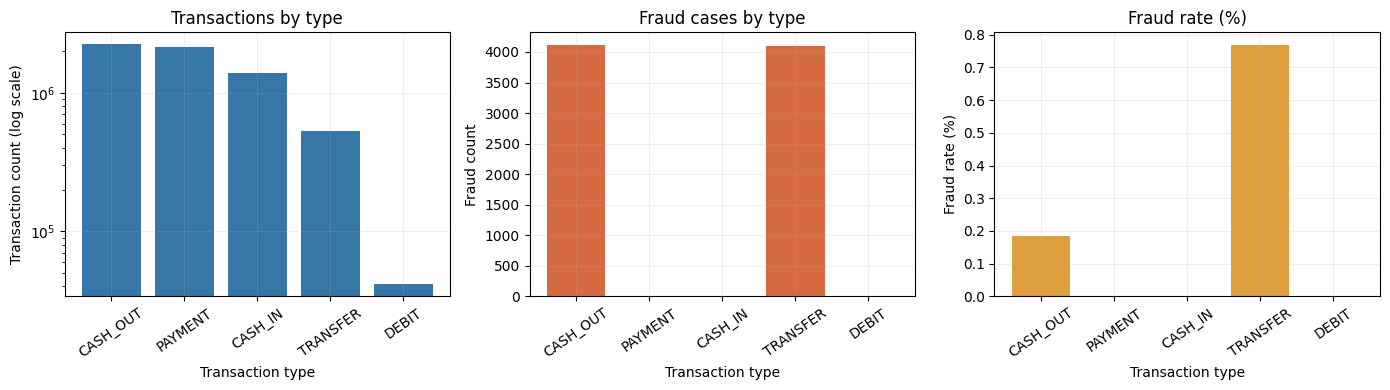

In [28]:
#Fraud by transaction type
fraud_by_type = run_sql("Fraud by transaction type", """
    SELECT type, COUNT(*) AS transactions, SUM(isFraud) AS fraud,
           100.0*AVG(isFraud) AS fraud_rate_pct,
           100.0*SUM(isFraud)/NULLIF(SUM(SUM(isFraud)) OVER (),0) AS share_of_all_fraud_pct
    FROM paysim GROUP BY type ORDER BY transactions DESC
""")
display(fraud_by_type)
save_table(fraud_by_type, "fraud_by_type")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

columns = ["transactions", "fraud", "fraud_rate_pct"]
titles = [
    "Transactions by type",
    "Fraud cases by type",
    "Fraud rate (%)"
]
colors = ["#3677A8", "#D66B42", "#E09F3E"]

for ax, column, title, color in zip(axes, columns, titles, colors):
    ax.bar(
        fraud_by_type["type"],
        fraud_by_type[column],
        color=color
    )

    ax.set_title(title)
    ax.set_xlabel("Transaction type")
    ax.tick_params(axis="x", rotation=35)

axes[0].set_yscale("log")
axes[0].set_ylabel("Transaction count (log scale)")
axes[1].set_ylabel("Fraud count")
axes[2].set_ylabel("Fraud rate (%)")

save_figure("fraud_by_type")

In [29]:
# How much does a type rule actually narrow the problem? (descriptive; labels used for description only)
tc_mask = fraud_by_type["type"].isin(["TRANSFER", "CASH_OUT"])
tc_tx = int(fraud_by_type.loc[tc_mask, "transactions"].sum())
tc_fraud = int(fraud_by_type.loc[tc_mask, "fraud"].sum())
overall_rate = 100.0 * int(fraud_by_type["fraud"].sum()) / int(fraud_by_type["transactions"].sum())
tc_rate = 100.0 * tc_fraud / tc_tx
type_rule_summary = pd.DataFrame([
    ("All transactions", int(fraud_by_type["transactions"].sum()), int(fraud_by_type["fraud"].sum()), overall_rate),
    ("TRANSFER + CASH_OUT only", tc_tx, tc_fraud, tc_rate),
], columns=["rows", "transactions", "fraud", "fraud_rate_pct"])
display(type_rule_summary)
save_table(type_rule_summary, "type_rule_summary")
print(f"Restricting to TRANSFER/CASH_OUT keeps {100*tc_fraud/max(int(fraud_by_type['fraud'].sum()),1):.1f}% of fraud "
      f"but raises the fraud rate only from {overall_rate:.4f}% to {tc_rate:.4f}% ({tc_rate/overall_rate:.1f}x).")

,rows,transactions,fraud,fraud_rate_pct
0,All transactions,6362620,8213,0.1291
1,TRANSFER + CASH_OUT only,2770409,8213,0.2965


Restricting to TRANSFER/CASH_OUT keeps 100.0% of fraud but raises the fraud rate only from 0.1291% to 0.2965% (2.3x).


### My interpretation

Fraud only shows up in `TRANSFER` (4,097 cases, 0.7688% fraud rate) and `CASH_OUT` (4,116 cases, 0.1840%); `PAYMENT`,
`CASH_IN` and `DEBIT` contain no fraud in this file. This is consistent with how PaySim injects fraud (transfer, then cash-out).

A type rule is a useful **pre-filter, but it does not solve the problem**. Together, `TRANSFER` and `CASH_OUT` hold 100%
of the fraud but still have a fraud rate of only about 0.30% (roughly 2.3 times the overall 0.13%). A rule that flags every
`TRANSFER`/`CASH_OUT` would be wrong about 99.7% of the time, so most of the separation work remains inside those two types.
I will keep all five types in the training data so that the models learn this split themselves, and I will also report
metrics on the `TRANSFER`/`CASH_OUT` subset because that is where the models have to work.

## 4. Transaction and fraud patterns over time

Inspect volume, fraud counts and fraud rates separately. Changes over time can make a chronological test set
different from training. Missing steps inside the observed range are shown as zero recorded transactions;
their fraud rate remains undefined. Simulation hours are not real calendar timestamps.

Missing hours in selected range: 0 | first examples: []


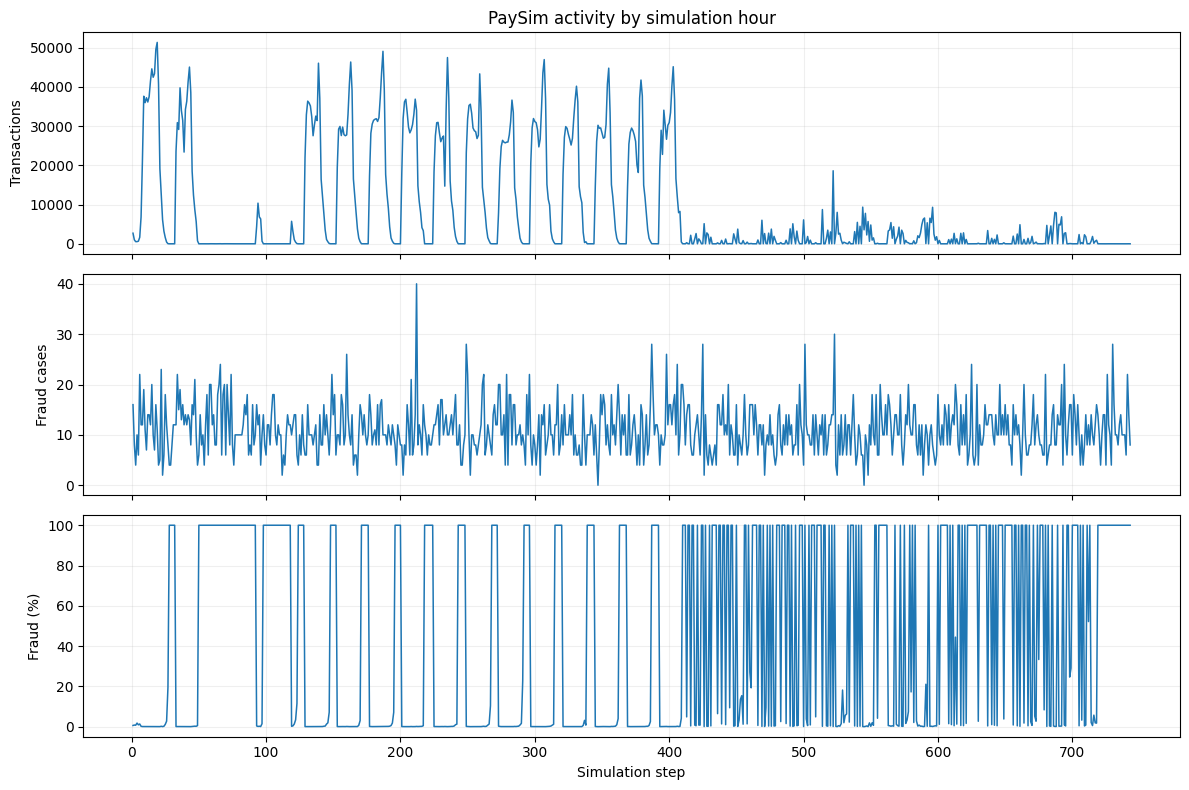

In [30]:
# Transaction and fraud patterns over time
full_steps = pd.RangeIndex(first_step, last_step + 1, name="step")
timeline = by_step.set_index("step").reindex(full_steps, fill_value=0).reset_index()
timeline["fraud_rate_pct"] = 100 * timeline["fraud"] / timeline["transactions"].replace(0, np.nan)
missing_steps = timeline.loc[timeline["transactions"] == 0, "step"].tolist()
save_table(timeline, "transactions_by_step")
print("Missing hours in selected range:", len(missing_steps), "| first examples:", missing_steps[:20])


fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, column, ylabel in zip(axes, ["transactions", "fraud", "fraud_rate_pct"],
                            ["Transactions", "Fraud cases", "Fraud (%)"]):
    ax.plot(timeline["step"], timeline[column], linewidth=1.1)
    ax.set_ylabel(ylabel)
axes[0].set_title("PaySim activity by simulation hour")
axes[-1].set_xlabel("Simulation step")
save_figure("time_patterns")

In [31]:
# Descriptive view: three equal-length periods of the timeline (boundaries do not depend on labels).
period_index = ((timeline["step"] - first_step) * 3 // (last_step - first_step + 1)).clip(0, 2)
timeline["period"] = period_index.map({0: "first third", 1: "middle third", 2: "last third"})
thirds = timeline.groupby("period", sort=False).agg(
    first_step=("step", "min"), last_step=("step", "max"), hours=("step", "count"),
    transactions=("transactions", "sum"), fraud=("fraud", "sum"))
thirds["transactions_per_hour"] = thirds["transactions"] / thirds["hours"]
thirds["fraud_per_hour"] = thirds["fraud"] / thirds["hours"]
thirds["fraud_rate_pct"] = 100 * thirds["fraud"] / thirds["transactions"]
display(thirds)
save_table(thirds.reset_index(), "time_thirds")

,first_step,last_step,hours,transactions,fraud,transactions_per_hour,fraud_per_hour,fraud_rate_pct
period,,,,,,,,
first third,1,248,248,3193229,"2,791.0000","12,875.9234",11.2540,0.0874
middle third,249,496,248,2862428,"2,724.0000","11,542.0484",10.9839,0.0952
last third,497,743,247,306963,"2,698.0000","1,242.7652",10.9231,0.8789


### My interpretation

Both the volume and the fraud rate change over the simulated month, so the three periods above are not alike.
The columns to compare are `transactions_per_hour` and `fraud_per_hour`: if fraud arrives at a roughly steady number of
cases per hour while overall volume per hour changes, the fraud **rate** moves with volume even though the fraud
process itself has not changed. Section 6 shows this on the actual train/validation/test boundaries and why it matters.
`step` is a simulation hour, not a calendar timestamp, so I only read hour-of-day (`step % 24`) as a possible cyclical
signal and do not interpret day or week effects.

## 5. Repeated senders and receivers

Lifetime repetition is an initial structural check. The table separates the percentage of **accounts** that repeat
from the percentage of **transactions** involving those accounts. The chart groups accounts by transaction count.
Repetition later in the dataset, or in the same hour, does not make history available for an earlier transaction.

,role,unique_accounts,repeating_accounts_pct,transactions_in_repeating_accounts_pct,multi_step_accounts_pct,median_transactions,max_transactions
0,sender,6353307,0.1463,0.2925,0.1456,1.0000,3
1,receiver,2722362,16.8845,64.4375,16.8442,1.0000,113


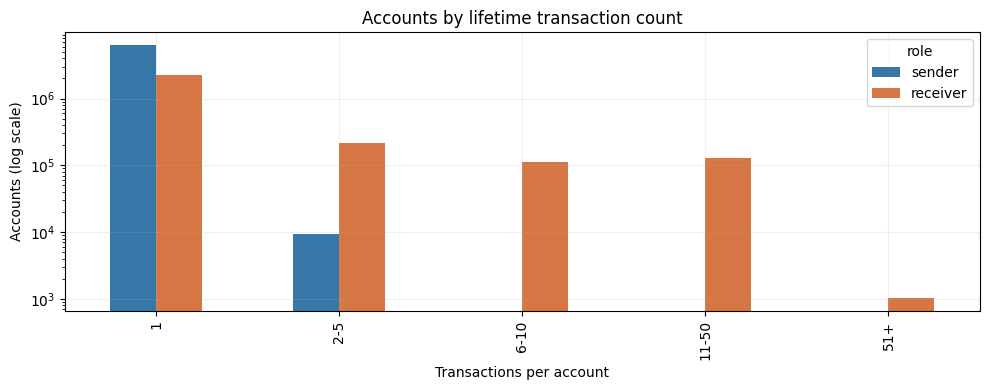

In [32]:
#Repeated senders and receivers
for role, account_column in [("sender", "nameOrig"), ("receiver", "nameDest")]:
    run_sql(f"{role} account profiles", f"""
        CREATE OR REPLACE TEMP TABLE {role}_profile AS
        SELECT {account_column} AS account, COUNT(*) AS transactions,
               COUNT(DISTINCT step) AS active_steps, MIN(step) AS first_step, MAX(step) AS last_step
        FROM paysim GROUP BY {account_column}
    """, fetch=False)

repetition_parts = []
bucket_parts = []
for role in ["sender", "receiver"]:
    repetition_parts.append(run_sql(f"{role} repetition summary", f"""
        SELECT '{role}' AS role, COUNT(*) AS unique_accounts,
               100.0*AVG(CASE WHEN transactions > 1 THEN 1 ELSE 0 END) AS repeating_accounts_pct,
               100.0*SUM(CASE WHEN transactions > 1 THEN transactions ELSE 0 END)/SUM(transactions) AS transactions_in_repeating_accounts_pct,
               100.0*AVG(CASE WHEN active_steps > 1 THEN 1 ELSE 0 END) AS multi_step_accounts_pct,
               MEDIAN(transactions) AS median_transactions, MAX(transactions) AS max_transactions
        FROM {role}_profile
    """))
    bucket_parts.append(run_sql(f"{role} repetition buckets", f"""
        SELECT '{role}' AS role,
               CASE WHEN transactions=1 THEN '1' WHEN transactions<=5 THEN '2-5'
                    WHEN transactions<=10 THEN '6-10' WHEN transactions<=50 THEN '11-50' ELSE '51+' END AS bucket,
               COUNT(*) AS accounts, SUM(transactions) AS transactions
        FROM {role}_profile GROUP BY bucket
    """))
repetition = pd.concat(repetition_parts, ignore_index=True)
buckets = pd.concat(bucket_parts, ignore_index=True)
display(repetition)
save_table(repetition, "account_repetition")
save_table(buckets, "account_repetition_buckets")

order = ["1", "2-5", "6-10", "11-50", "51+"]
bucket_plot = buckets.pivot(index="bucket", columns="role", values="accounts").reindex(index=order, columns=["sender", "receiver"]).fillna(0)
bucket_plot.plot.bar(figsize=(10,4), logy=True, color=["#3677a8", "#d57644"])
plt.title("Accounts by lifetime transaction count")
plt.xlabel("Transactions per account")
plt.ylabel("Accounts (log scale)")
save_figure("account_repetition")

### My interpretation

Senders and receivers behave completely differently here. Only 0.1463% of sender accounts (median 1 transaction, max 3)
ever transact more than once, but 16.88% of receiver accounts do, and those repeating receivers account for 64.44% of all
transactions (median still 1, but max 113). The repeating receivers are probably dominated by reused destinations such as
merchants (`M`-prefixed accounts) and cash-out agents; Section 7b checks this directly instead of assuming it.
Practically, graph-style features (fan-in, repeat-counterparty signals) are unlikely to provide sufficient historical coverage on the sender side but a real
chance on the receiver side, before I have even applied the strictly-earlier-history rule in the next sections.

## 6. Proposed chronological train / validation / test split

The proposal targets approximately **60% / 20% / 20% of transaction volume**, keeping each hour in one split.
Boundaries depend on time and transaction counts, not labels. Fraud counts describe the resulting imbalance;
they are not a reason to move boundaries until a preferred result appears.

Confirm this protocol before modelling. Fit encoders and scalers on training data only, use validation for choices,
and reserve test data for the final comparison. Full-period charts are exploratory descriptions and must not guide
choices using test labels. Past unlabelled activity may remain available across split boundaries in a sequential evaluation.

In [33]:
#Proposed chronological train / validation / test split
split_boundaries = None
if len(by_step) < 3:
    raise RuntimeError("Fewer than three observed steps: no three-way split possible. Increase MAX_STEP or use the full file.")

cumulative = by_step["transactions"].cumsum().to_numpy()
m = len(by_step)
train_i = int(np.clip(np.searchsorted(cumulative, 0.60*n), 0, m-3))
validation_i = int(np.clip(np.searchsorted(cumulative, 0.80*n), train_i+1, m-2))
train_end = int(by_step.iloc[train_i]["step"])
validation_end = int(by_step.iloc[validation_i]["step"])
split_boundaries = {"train_end_step": train_end, "validation_end_step": validation_end}

SPLIT_NAMES = ["train", "validation", "test"]
SPLIT_SQL = f"CASE WHEN p.step <= {train_end} THEN 'train' WHEN p.step <= {validation_end} THEN 'validation' ELSE 'test' END"
# Row scopes used by the history/coverage tables (column name `step`).
scopes = [("all", "TRUE"),
          ("train", f"step <= {train_end}"),
          ("validation", f"step > {train_end} AND step <= {validation_end}"),
          ("test", f"step > {validation_end}")]

split_audit = run_sql("Chronological split summary", f"""
    SELECT CASE WHEN step <= {train_end} THEN 'train'
                WHEN step <= {validation_end} THEN 'validation' ELSE 'test' END AS split,
           MIN(step) AS first_step, MAX(step) AS last_step, COUNT(DISTINCT step) AS hours,
           COUNT(*) AS transactions, 100.0*COUNT(*)/{n} AS share_pct,
           1.0*COUNT(*)/COUNT(DISTINCT step) AS transactions_per_hour,
           SUM(isFraud) AS fraud,
           100.0*SUM(isFraud)/NULLIF(SUM(SUM(isFraud)) OVER (), 0) AS share_of_all_fraud_pct,
           1.0*SUM(isFraud)/COUNT(DISTINCT step) AS fraud_per_hour,
           100.0*AVG(isFraud) AS fraud_rate_pct
    FROM paysim GROUP BY split ORDER BY first_step
""")
split_audit["fraud_rate_ratio_vs_train"] = split_audit["fraud_rate_pct"] / (float(split_audit.loc[0, "fraud_rate_pct"]) or np.nan)
display(split_audit)
save_table(split_audit, "proposed_time_splits")
assert int(split_audit["transactions"].sum()) == n
assert len(split_audit) == 3
if (split_audit["fraud"] == 0).any():
    print("A split has no fraud. Some metrics will be undefined; discuss the protocol.")

,split,first_step,last_step,hours,transactions,share_pct,transactions_per_hour,fraud,share_of_all_fraud_pct,fraud_per_hour,fraud_rate_pct,fraud_rate_ratio_vs_train
0,train,1,281,281,3820599,60.0476,"13,596.4377","3,193.0000",38.8774,11.3630,0.0836,1.0000
1,validation,282,355,74,1293285,20.3263,"17,476.8243",770.0000,9.3754,10.4054,0.0595,0.7124
2,test,356,743,388,1248736,19.6261,"3,218.3918","4,250.0000",51.7472,10.9536,0.3403,4.0724


In [34]:
# Distribution shift across the split (descriptive; the boundaries above were fixed without labels).
shift = split_audit.set_index("split")
f = lambda s, c: float(shift.loc[s, c])
shift_lines = [
    "Fraud rate: " + " | ".join(f"{s} {f(s, 'fraud_rate_pct'):.4f}%" for s in SPLIT_NAMES)
    + f"  (test is {f('test','fraud_rate_pct')/f('train','fraud_rate_pct'):.1f}x the training rate)",
    f"Share of all fraud cases that fall in the test period: {f('test','share_of_all_fraud_pct'):.1f}%",
    "Transactions per hour: " + " | ".join(f"{s} {f(s, 'transactions_per_hour'):,.0f}" for s in SPLIT_NAMES),
    "Fraud cases per hour: " + " | ".join(f"{s} {f(s, 'fraud_per_hour'):.1f}" for s in SPLIT_NAMES),
]
print("\n".join(shift_lines))

Fraud rate: train 0.0836% | validation 0.0595% | test 0.3403%  (test is 4.1x the training rate)
Share of all fraud cases that fall in the test period: 51.7%
Transactions per hour: train 13,596 | validation 17,477 | test 3,218
Fraud cases per hour: train 11.4 | validation 10.4 | test 11.0


### My interpretation: distribution shift

The split is not stationary. The fraud rate is **0.084% in training, 0.060% in validation and 0.340% in test**, so the
test period has about **four times** the training fraud rate, and it holds about **52% of all fraud cases** (4,250 of 8,213).
The per-hour table explains why: fraud cases arrive at roughly 10-11 per hour in every period, but the number of
transactions per hour is about 13.6k in training and 17.5k in validation against only about 3.2k in test. The test fraud
rate is higher mainly because there are far fewer legitimate transactions per hour, not because there is more fraud per hour.

This affects the evaluation design:

* **Metrics depend on prevalence.** Precision and PR-AUC are not comparable across splits unless they are read against each
  split's own base rate. I will report PR-AUC next to the prevalence, plus recall at a fixed **alert rate** (e.g. top 0.1% of
  transactions), rather than relying on ROC-AUC alone.
* **Score thresholds will not transfer.** A threshold tuned on validation (0.06% fraud) will behave differently on test (0.34%).
  I will choose operating points by alert rate or rank, not by a fixed raw score, and I will say so when reporting.
* **Raw `step` is not a safe feature.** Test steps lie entirely outside the training range, so I will use hour-of-day (`step % 24`) instead.
* **One split is a thin basis for conclusions.** I plan to add rolling time-blocked folds as a robustness check.
* **Unsupervised contamination.** Isolation Forest and LOF settings (e.g. contamination) should not be copied from the test prevalence.

## 7. History available in the previous 6, 24 and 48 hours

Group by account and hour, then use `LAG(step)` to find the previous **distinct** hour. For a 24-hour window at
hour `t`, history must satisfy `t - 24 <= earlier_step < t`. Two transactions in an account's first hour both have
no prior history. At hour 34, activity at hour 10 is included; at hour 35, it is outside that window.

Coverage means the percentage of **transactions** with at least one qualifying earlier transaction in the same role.
It does not measure a feature's predictive value. The table reports coverage for all rows and **separately for train,
validation and test**, because the three periods have very different volumes per hour (Section 6).
Early observations have less possible history because nothing before the file is known.

scope                    all_pct  train_pct  validation_pct  test_pct
role     window                                                      
receiver any_prior_step  56.4660    56.2042         57.3538   56.3476
         prior_24h       37.0007    44.8917         30.7927   19.2873
         prior_48h       45.9878    51.4340         45.1222   30.2215
         prior_6h        21.3561    28.5686         13.1207    7.8183
sender   any_prior_step   0.1456     0.0887          0.2078    0.2555
         prior_24h        0.0174     0.0171          0.0204    0.0149
         prior_48h        0.0312     0.0305          0.0380    0.0263
         prior_6h         0.0059     0.0063          0.0056    0.0048

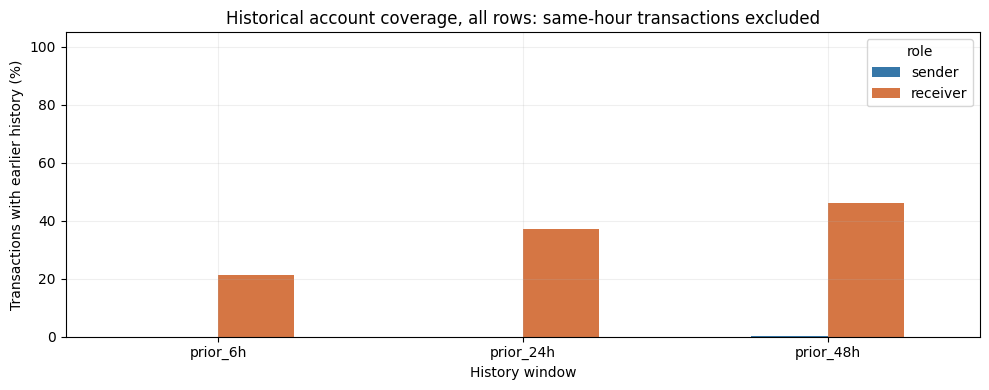

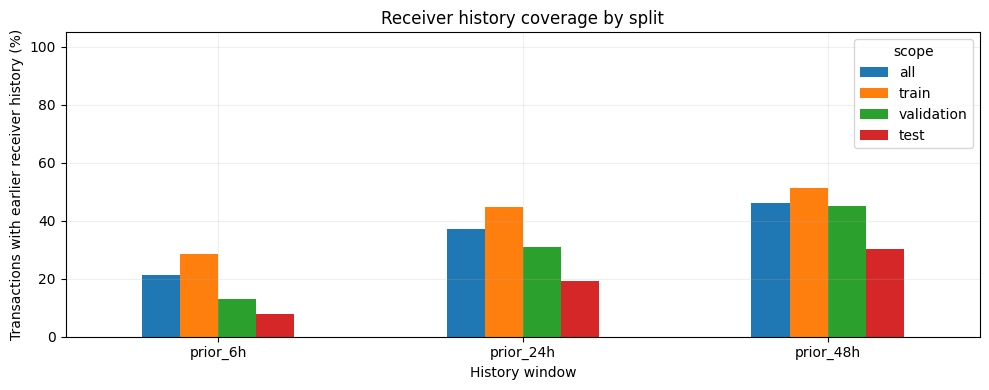

In [35]:
# Labels are deliberately absent from the account-history tables.
for role, account_column in [("sender", "nameOrig"), ("receiver", "nameDest")]:
    run_sql(f"{role} history", f"""
        CREATE OR REPLACE TEMP TABLE {role}_history AS
        WITH activity AS (
            SELECT {account_column} AS account, step, COUNT(*) AS transactions
            FROM paysim GROUP BY {account_column}, step
        )
        SELECT *, LAG(step) OVER (PARTITION BY account ORDER BY step) AS previous_step
        FROM activity
    """, fetch=False)

history_conditions = [("any_prior_step", "previous_step IS NOT NULL")]
history_conditions += [(f"prior_{w}h", f"step - previous_step BETWEEN 1 AND {w}") for w in WINDOWS]
SCOPE_ORDER = [s for s, _ in scopes]

coverage_rows = []
for role in ["sender", "receiver"]:
    window_counts = ", ".join(
        f"SUM(CASE WHEN {condition} THEN transactions ELSE 0 END) AS {window}"
        for window, condition in history_conditions
    )
    for scope, where in scopes:
        counts = con.execute(f"SELECT SUM(transactions), {window_counts} FROM {role}_history WHERE {where}").fetchone()
        denominator = int(counts[0])
        for (window, _), covered in zip(history_conditions, counts[1:]):
            coverage_rows.append({"role": role, "window": window, "scope": scope,
                                  "transactions": denominator, "covered_transactions": int(covered),
                                  "coverage_pct": 100.0 * int(covered) / denominator})
coverage = pd.DataFrame(coverage_rows)
coverage_comparison = (coverage.pivot(index=["role", "window"], columns="scope", values="coverage_pct")
                       [SCOPE_ORDER].add_suffix("_pct"))
display(coverage_comparison)
save_table(coverage, "historical_coverage")

window_order = [f"prior_{w}h" for w in WINDOWS]
coverage[coverage["scope"] == "all"].pivot(index="window", columns="role", values="coverage_pct").reindex(
    index=window_order, columns=["sender", "receiver"]
).plot.bar(figsize=(10, 4), color=["#3677a8", "#d57644"])
plt.ylim(0, 105)
plt.ylabel("Transactions with earlier history (%)")
plt.xlabel("History window")
plt.xticks(rotation=0)
plt.title("Historical account coverage, all rows: same-hour transactions excluded")
save_figure("historical_coverage")

coverage[coverage["role"] == "receiver"].pivot(index="window", columns="scope", values="coverage_pct").reindex(
    index=window_order, columns=SCOPE_ORDER
).plot.bar(figsize=(10, 4))
plt.ylim(0, 105)
plt.ylabel("Transactions with earlier receiver history (%)")
plt.xlabel("History window")
plt.xticks(rotation=0)
plt.title("Receiver history coverage by split")
save_figure("receiver_coverage_by_split")

### My interpretation

Once same-hour activity is excluded, **sender history is close to unusable**: only 0.0174% of transactions (all rows) have a
sender with any activity in the prior 24 hours, and it is just as low in every split in the table above. Sender history needs a
cold-start flag at best.

**Receiver history is a different story, but its coverage is not constant across splits.** The overall 24h figure (37.0%) is a
weighted mean of the three periods (weights about 0.60/0.20/0.20). With 44.9% in training, the validation and test periods must
average only about 25%. This is not "more history early in the simulation"; it is a **volume effect**. A receiver can only repeat
within 24 hours if enough transactions arrive per hour, and test hours are much sparser (about 3.2k per hour against 13.6k in
training, Section 6). So a receiver feature trained on dense history will see much sparser history at test time. Receiver
features should therefore be evaluated per split, and I should expect the test period to be the hardest for them.

## 7b. Receiver history on the rows that matter: TRANSFER and CASH_OUT

Fraud only occurs in `TRANSFER` and `CASH_OUT`, so coverage computed over all rows may overstate how useful receiver history
is. Repeating receivers are probably dominated by merchants (`M`-prefixed accounts, mostly `PAYMENT` rows), which can never be
fraudulent here. This section recomputes receiver coverage on `TRANSFER`/`CASH_OUT` rows only. The history itself still counts
all earlier incoming transactions, because that is the information a real feature could use. No labels are used.

In [36]:
window_exprs = ", ".join(
    f"100.0*AVG(CASE WHEN h.previous_step IS NOT NULL AND p.step - h.previous_step <= {w} THEN 1 ELSE 0 END) AS prior_{w}h_pct"
    for w in WINDOWS
)
GROUP_SQL = "CASE WHEN p.type IN ('TRANSFER','CASH_OUT') THEN 'TRANSFER/CASH_OUT' ELSE 'other types' END"
join_sql = "FROM paysim p JOIN receiver_history h ON h.account = p.nameDest AND h.step = p.step"

tc_cov = run_sql("Receiver coverage by row group and split", f"""
    SELECT {GROUP_SQL} AS row_group, {SPLIT_SQL} AS split, COUNT(*) AS transactions, {window_exprs}
    {join_sql} GROUP BY 1, 2
""")
tc_cov["split"] = pd.Categorical(tc_cov["split"], SPLIT_NAMES, ordered=True)
tc_cov = tc_cov.sort_values(["row_group", "split"]).reset_index(drop=True)
display(tc_cov)
save_table(tc_cov, "receiver_coverage_tc_vs_other")

prefix_cov = run_sql("Receiver coverage by receiver prefix", f"""
    SELECT {GROUP_SQL} AS row_group, substr(p.nameDest, 1, 1) AS receiver_prefix, {SPLIT_SQL} AS split,
           COUNT(*) AS transactions, {window_exprs}
    {join_sql} GROUP BY 1, 2, 3
""")
prefix_cov["share_of_group_split_pct"] = 100 * prefix_cov["transactions"] / prefix_cov.groupby(["row_group", "split"])["transactions"].transform("sum")
prefix_cov["split"] = pd.Categorical(prefix_cov["split"], SPLIT_NAMES, ordered=True)
prefix_cov = prefix_cov.sort_values(["row_group", "receiver_prefix", "split"]).reset_index(drop=True)
display(prefix_cov)
save_table(prefix_cov, "receiver_coverage_by_prefix")

all_rows_24 = coverage[(coverage["role"] == "receiver") & (coverage["window"] == "prior_24h")].set_index("scope")["coverage_pct"]
tc_lines = []
for s in SPLIT_NAMES:
    tc_val = float(tc_cov[(tc_cov["row_group"] == "TRANSFER/CASH_OUT") & (tc_cov["split"] == s)]["prior_24h_pct"].iloc[0])
    tc_lines.append(f"Receiver prior-24h coverage, {s}: all rows {all_rows_24[s]:.2f}% | TRANSFER/CASH_OUT rows only {tc_val:.2f}%")
print("\n".join(tc_lines))
tc_train_24 = float(tc_cov[(tc_cov["row_group"] == "TRANSFER/CASH_OUT") & (tc_cov["split"] == "train")]["prior_24h_pct"].iloc[0])

,row_group,split,transactions,prior_6h_pct,prior_24h_pct,prior_48h_pct
0,TRANSFER/CASH_OUT,train,1672907,42.9597,67.3703,77.1736
1,TRANSFER/CASH_OUT,validation,565562,19.6424,46.0073,67.3580
2,TRANSFER/CASH_OUT,test,531940,12.0015,29.5103,46.1037
3,other types,train,2147692,17.3590,27.3823,31.3845
4,other types,validation,727723,8.0522,18.9685,27.8414
5,other types,test,716796,4.7139,11.7008,18.4352


,row_group,receiver_prefix,split,transactions,prior_6h_pct,prior_24h_pct,prior_48h_pct,share_of_group_split_pct
0,TRANSFER/CASH_OUT,C,train,1672907,42.9597,67.3703,77.1736,100.0000
1,TRANSFER/CASH_OUT,C,validation,565562,19.6424,46.0073,67.3580,100.0000
2,TRANSFER/CASH_OUT,C,test,531940,12.0015,29.5103,46.1037,100.0000
3,other types,C,train,860533,43.3209,68.3315,78.3138,40.0678
4,other types,C,validation,294474,19.8968,46.8683,68.7881,40.4651
5,other types,C,test,285709,11.8225,29.3484,46.2355,39.8592
6,other types,M,train,1287159,0.0020,0.0056,0.0098,59.9322
7,other types,M,validation,433249,0.0016,0.0053,0.0104,59.5349
8,other types,M,test,431087,0.0026,0.0046,0.0102,60.1408


Receiver prior-24h coverage, train: all rows 44.89% | TRANSFER/CASH_OUT rows only 67.37%
Receiver prior-24h coverage, validation: all rows 30.79% | TRANSFER/CASH_OUT rows only 46.01%
Receiver prior-24h coverage, test: all rows 19.29% | TRANSFER/CASH_OUT rows only 29.51%


### My interpretation

The printed lines compare receiver coverage on all rows with coverage on `TRANSFER`/`CASH_OUT` rows for each split. Read them
together with the prefix table: if `C`-prefixed receivers dominate `TRANSFER`/`CASH_OUT` rows and the merchant share is
concentrated in other types, then the headline receiver coverage mostly describes `PAYMENT` traffic and **overstates** how much
history the fraud-relevant rows have. The number that goes into the feature plan (Section 10) is the `TRANSFER`/`CASH_OUT`
training coverage, not the all-row figure. Coverage on these rows is also what I will report per split when I discuss receiver features.

## 8. Compact pair and flow feasibility check

A directed pair is a specific sender–receiver combination. Count lifetime pair repetition, then separately check
whether each transaction's pair appeared at an **earlier hour**. For flow, check whether the current sender ever
received a transaction at an earlier hour. Joining the first observed hour is sufficient for these existence checks.

These two historical checks use **any earlier step**, not a 24-hour window. They do not measure money forwarded,
flow amounts or fraudulent intent. Detailed windowed pair and incoming/outgoing features can be investigated later.

In [37]:
run_sql("Pair profiles", """
    CREATE OR REPLACE TEMP TABLE pair_profile AS
    SELECT nameOrig, nameDest, COUNT(*) AS transactions, MIN(step) AS first_step
    FROM paysim GROUP BY nameOrig, nameDest
""", fetch=False)
unique_pairs, repeated_pairs = con.execute("""
    SELECT COUNT(*), COUNT(*) FILTER (WHERE transactions > 1) FROM pair_profile
""").fetchone()
unique_pairs, repeated_pairs = int(unique_pairs), int(repeated_pairs)
rows_sharing_a_pair = n - unique_pairs   # 0 means no two rows share a sender-receiver pair, hence no exact duplicate rows

# First occurrence is used only to ask whether something happened strictly before the current hour.
pair_conditions = [
    f"100.0 * COUNT(*) FILTER (WHERE p.step > q.first_step AND {where}) / NULLIF(COUNT(*) FILTER (WHERE {where}), 0) AS {scope}"
    for scope, where in [(s, w.replace("step", "p.step")) for s, w in scopes]
]
pair_percentages = con.execute(f"""
    SELECT {', '.join(pair_conditions)} FROM paysim p JOIN pair_profile q USING (nameOrig, nameDest)
""").fetchone()
flow_conditions = [
    f"100.0 * SUM(CASE WHEN s.step > r.first_step AND {where} THEN s.transactions ELSE 0 END) / NULLIF(SUM(CASE WHEN {where} THEN s.transactions ELSE 0 END), 0) AS {scope}"
    for scope, where in [(s, w.replace("step", "s.step")) for s, w in scopes]
]
flow_percentages = con.execute(f"""
    SELECT {', '.join(flow_conditions)}
    FROM sender_history s LEFT JOIN receiver_profile r USING (account)
""").fetchone()
pair_coverage = dict(zip(SCOPE_ORDER, map(float, pair_percentages)))
flow_coverage = dict(zip(SCOPE_ORDER, map(float, flow_percentages)))

pad = (np.nan,) * (len(SCOPE_ORDER) - 1)
pair_flow_summary = pd.DataFrame([
    ("Unique directed pairs", "pairs", unique_pairs) + pad,
    ("Pairs occurring more than once (lifetime)", "pairs", repeated_pairs) + pad,
    ("Transaction pair seen at an earlier hour", "% of transactions") + tuple(pair_coverage[s] for s in SCOPE_ORDER),
    ("Sender received a transaction at an earlier hour", "% of transactions") + tuple(flow_coverage[s] for s in SCOPE_ORDER),
], columns=["check", "unit"] + [f"{s}_rows" for s in SCOPE_ORDER])
display(pair_flow_summary)
save_table(pair_flow_summary, "pair_and_flow_feasibility")
print(f"Rows minus unique pairs = {rows_sharing_a_pair:,}: "
      + ("every row has its own sender-receiver pair, so there are no exact duplicate rows." if rows_sharing_a_pair == 0
         else "some rows share a pair; exact duplicates need a separate check."))
_ = con.execute("DROP TABLE pair_profile")

,check,unit,all_rows,train_rows,validation_rows,test_rows
0,Unique directed pairs,pairs,"6,362,620.0000",NaN,NaN,NaN
1,Pairs occurring more than once (lifetime),pairs,0.0000,NaN,NaN,NaN
2,Transaction pair seen at an earlier hour,% of transactions,0.0000,0.0000,0.0000,0.0000
3,Sender received a transaction at an earlier hour,% of transactions,0.0141,0.0094,0.0208,0.0218


Rows minus unique pairs = 0: every row has its own sender-receiver pair, so there are no exact duplicate rows.


### My interpretation

Zero repeated pairs (0 of 6,362,620) means that every transaction is between a sender-receiver pair that never transacted before,
so a "pair novelty" or "repeat pair count" feature would be **constant** for the whole dataset. I am dropping it rather than
deferring it. The same fact also means unique pairs equal rows, so there are **no exact duplicate rows** (two identical rows
would share a pair).

The flow-through signal (sender received money at an earlier hour) covers only 0.0141% of rows overall and 0.0094% of training
rows. Low coverage is not the same as low value: a handful of rows can still be informative if they are mostly fraud. Whether it
deserves a place in the feature set is decided by the label check in Section 9, not by coverage alone.

## 9. Does history carry any fraud signal? (training rows only)

Coverage tells me where a feature *can* vary, not whether it *helps*. This check uses **training rows only** to compare fraud
rates with and without each history flag. It is a feasibility screen, not model evaluation: validation and test labels are not
used. Because all fraud sits in `TRANSFER`/`CASH_OUT`, the check is repeated on those rows only; otherwise a flag could look
informative merely because it correlates with transaction type.

Flags: `receiver_prior_24h` (the receiver had incoming activity in the previous 24 hours) and `sender_received_earlier`
(the sender received money at an earlier hour, the flow-through idea).

In [38]:
def fraud_by_history_flag(label, row_filter):
    return run_sql(label, f"""
        WITH r AS (SELECT account, step,
                          (previous_step IS NOT NULL AND step - previous_step <= 24) AS flag
                   FROM receiver_history)
        SELECT 'receiver_prior_24h' AS feature, r.flag AS flag, COUNT(*) AS transactions,
               SUM(p.isFraud) AS fraud, 100.0*AVG(p.isFraud) AS fraud_rate_pct
        FROM paysim p JOIN r ON r.account = p.nameDest AND r.step = p.step
        WHERE p.step <= {train_end} AND {row_filter} GROUP BY 1, 2
        UNION ALL
        SELECT 'sender_received_earlier', COALESCE(p.step > f.first_step, FALSE),
               COUNT(*), SUM(p.isFraud), 100.0*AVG(p.isFraud)
        FROM paysim p LEFT JOIN receiver_profile f ON f.account = p.nameOrig
        WHERE p.step <= {train_end} AND {row_filter} GROUP BY 1, 2
    """).sort_values(["feature", "flag"]).reset_index(drop=True)

label_check_all = fraud_by_history_flag("Fraud rate by history flag (train, all rows)", "TRUE")
label_check_tc = fraud_by_history_flag("Fraud rate by history flag (train, TRANSFER/CASH_OUT)", "p.type IN ('TRANSFER','CASH_OUT')")
print("Training rows, all types"); display(label_check_all)
print("Training rows, TRANSFER/CASH_OUT only"); display(label_check_tc)
save_table(label_check_all, "history_flag_fraud_rate_train_all")
save_table(label_check_tc, "history_flag_fraud_rate_train_tc")

def describe_flags(table, scope_label, min_cases=30):
    lines = []
    for feature, g in table.groupby("feature"):
        g = g.set_index("flag")
        if True not in g.index or False not in g.index:
            lines.append(f"[{scope_label}] {feature}: only one flag value occurs in training; no comparison possible.")
            continue
        t, f_ = g.loc[True], g.loc[False]
        ratio = float(t["fraud_rate_pct"]) / float(f_["fraud_rate_pct"]) if float(f_["fraud_rate_pct"]) > 0 else float("nan")
        note = f" (only {int(t['fraud'])} fraud cases with the flag: too few to conclude)" if int(t["fraud"]) < min_cases else ""
        lines.append(f"[{scope_label}] {feature}: fraud rate {float(t['fraud_rate_pct']):.4f}% with flag ({int(t['fraud']):,} of {int(t['transactions']):,}) "
                     f"vs {float(f_['fraud_rate_pct']):.4f}% without ({int(f_['fraud']):,} of {int(f_['transactions']):,}); ratio {ratio:.2f}x{note}")
    return lines

flag_lines = describe_flags(label_check_all, "all types") + describe_flags(label_check_tc, "TRANSFER/CASH_OUT")
print("\n".join(flag_lines))

Training rows, all types


,feature,flag,transactions,fraud,fraud_rate_pct
0,receiver_prior_24h,False,2105469,"2,461.0000",0.1169
1,receiver_prior_24h,True,1715130,732.0000,0.0427
2,sender_received_earlier,False,3820240,"3,193.0000",0.0836
3,sender_received_earlier,True,359,0.0000,0.0000


Training rows, TRANSFER/CASH_OUT only


,feature,flag,transactions,fraud,fraud_rate_pct
0,receiver_prior_24h,False,545864,"2,461.0000",0.4508
1,receiver_prior_24h,True,1127043,732.0000,0.0649
2,sender_received_earlier,False,1672760,"3,193.0000",0.1909
3,sender_received_earlier,True,147,0.0000,0.0000


[all types] receiver_prior_24h: fraud rate 0.0427% with flag (732 of 1,715,130) vs 0.1169% without (2,461 of 2,105,469); ratio 0.37x
[all types] sender_received_earlier: fraud rate 0.0000% with flag (0 of 359) vs 0.0836% without (3,193 of 3,820,240); ratio 0.00x (only 0 fraud cases with the flag: too few to conclude)
[TRANSFER/CASH_OUT] receiver_prior_24h: fraud rate 0.0649% with flag (732 of 1,127,043) vs 0.4508% without (2,461 of 545,864); ratio 0.14x
[TRANSFER/CASH_OUT] sender_received_earlier: fraud rate 0.0000% with flag (0 of 147) vs 0.1909% without (3,193 of 1,672,760); ratio 0.00x (only 0 fraud cases with the flag: too few to conclude)


### My interpretation

Read the `TRANSFER`/`CASH_OUT` lines first, since the all-types lines mix in transaction type. The decision rules I will apply:

* **Receiver flag.** If fraud rates differ clearly between flagged and unflagged `TRANSFER`/`CASH_OUT` rows, receiver history
  carries real signal and the windowed receiver features are worth building. If they are close to equal, receiver history is
  mostly a volume proxy and I should say so.
* **Sender flow-through.** If the few flagged rows have a much higher fraud rate and enough fraud cases (the printed line warns
  when there are fewer than 30), keep it as a simple binary flag even though its coverage is only about 0.01%. If not, defer it
  as planned.
* All numbers come from training rows. Nothing here is tuned on validation or test labels.

## 10. Preliminary graph-feature plan

The evidence below uses training rows and unlabelled history coverage (Section 9 adds a label screen on training rows).
Coverage is classified with explicit thresholds so the wording is consistent:

| Training coverage | Assessment |
|---|---|
| exactly 0% | constant, drop |
| below 1% | very sparse: defer, at most a cold-start flag |
| 1% to 10% | sparse: optional |
| 10% or more | adequate: build first |

These are **proposed features**, not features already implemented by this audit. Positive coverage justifies checking feature
variation; higher coverage does not prove better detection. Build the transaction-only baseline first, then the receiver-side
historical counts, amounts, unique senders (fan-in) and the **change between adjacent windows**, which is the temporal aspect
my supervisor asked me to keep in mind. Compare under the same chronological protocol before drawing performance conclusions.

In [39]:
# Essential consistency checks remain, without a separate diagnostics report.
for role in ["sender", "receiver"]:
    bad, total = con.execute(f"""
        SELECT COUNT(*) FILTER (WHERE previous_step >= step), SUM(transactions)
        FROM {role}_history
    """).fetchone()
    assert bad == 0 and int(total) == n
assert int(fraud_by_type["transactions"].sum()) == n
assert int(timeline["transactions"].sum()) == n
assert coverage["coverage_pct"].between(0, 100).all()
for _, group in coverage.groupby(["role", "scope"]):
    counts = group.set_index("window")["covered_transactions"]
    ordered = [int(counts[f"prior_{w}h"]) for w in sorted(WINDOWS)] + [int(counts["any_prior_step"])]
    assert all(a <= b for a, b in zip(ordered, ordered[1:]))
for role in ["sender", "receiver"]:   # the three splits must add up to all rows
    parts = coverage[(coverage["role"] == role) & (coverage["window"] == "any_prior_step")].set_index("scope")["transactions"]
    assert int(parts[SPLIT_NAMES].sum()) == int(parts["all"]) == n
assert int(tc_cov["transactions"].sum()) == n
assert all(0 <= x <= 100 for x in list(pair_coverage.values()) + list(flow_coverage.values()))

def get_coverage(role, window="prior_24h", scope="train"):
    chosen = coverage[(coverage["role"] == role) & (coverage["window"] == window) & (coverage["scope"] == scope)]
    return float(chosen["coverage_pct"].iloc[0]) if len(chosen) else np.nan

def coverage_tier(x):
    if pd.isna(x):
        return "Not assessed"
    if x == 0:
        return "Constant (no prior history): drop"
    if x < 1:
        return "Extremely limited and unsupported by observed training fraud: exclude from the primary feature set"
    if x < 10:
        return "Sparse (1-10%): optional"
    return "Adequate (>=10%): build first"

feature_plan = pd.DataFrame([
    ("Receiver count / amount / unique senders (fan-in), all rows", get_coverage("receiver"), "Receiver activity in prior 24h",
     "Build first: windowed counts, amounts, unique senders for 6/24/48h"),
    ("Receiver features, TRANSFER/CASH_OUT rows only", tc_train_24, "Receiver activity in prior 24h on fraud-relevant types",
     "Use this figure to judge usefulness; report per split"),
    ("Change in receiver degree between adjacent windows", np.nan, "Needs history in two adjacent windows (not yet measured)",
     "Build after the window counts: e.g. (0-24h count) vs (24-48h count)"),
    ("Sender count / amount / fan-out", get_coverage("sender"), "Sender activity in prior 24h",
     "Defer; cold-start flag only"),
    ("Counterparty (pair) novelty", pair_coverage["train"], "Same pair at any earlier hour",
     "Exclude from the primary feature set because it has no variation in this dataset"),
    ("Incoming/outgoing flow-through", flow_coverage["train"], "Sender received at any earlier hour",
     "Exclude from the primary feature set; retain only as an optional robustness ablation among flagged rows"),
], columns=["candidate", "training_history_coverage_pct", "coverage_definition", "proposed_action"])
feature_plan["assessment"] = feature_plan["training_history_coverage_pct"].map(coverage_tier)
display(feature_plan)
save_table(feature_plan, "feature_development_plan")
print("Consistency checks passed. Coverage measures feasibility, not model performance.")

,candidate,training_history_coverage_pct,coverage_definition,proposed_action,assessment
0,Receiver count / amount / unique senders (fan-...,44.8917,Receiver activity in prior 24h,"Build first: windowed counts, amounts, unique ...",Adequate (>=10%): build first
1,"Receiver features, TRANSFER/CASH_OUT rows only",67.3703,Receiver activity in prior 24h on fraud-releva...,Use this figure to judge usefulness; report pe...,Adequate (>=10%): build first
2,Change in receiver degree between adjacent win...,NaN,Needs history in two adjacent windows (not yet...,Build after the window counts: e.g. (0-24h cou...,Not assessed
3,Sender count / amount / fan-out,0.0171,Sender activity in prior 24h,Defer; cold-start flag only,Extremely limited and unsupported by observed ...
4,Counterparty (pair) novelty,0.0000,Same pair at any earlier hour,Exclude from the primary feature set because i...,Constant (no prior history): drop
5,Incoming/outgoing flow-through,0.0094,Sender received at any earlier hour,Exclude from the primary feature set; retain o...,Extremely limited and unsupported by observed ...


Consistency checks passed. Coverage measures feasibility, not model performance.


### My interpretation

Putting the numbers side by side gives a clear build order. **Transaction baseline first** (no history needed), then **receiver-side
windowed features** (counts, amounts, unique senders, and the change in degree between adjacent windows). Receiver history is the
only family with real support; its usefulness is judged on the `TRANSFER`/`CASH_OUT` coverage and the Section 9 fraud-rate
comparison, not on the headline coverage.

* Sender fan-out (about 0.017%) falls in the "very sparse" tier and is deferred, with at most a cold-start flag.
* Pair novelty is constant (0%) and is dropped.
* Flow-through (about 0.009%) is also "very sparse"; I keep it only as a single binary flag, and only if the Section 9 line shows a
  meaningful fraud rate among enough flagged cases.

This is a narrower graph component than the one in my original email (degree, velocity, novelty, fan-in/fan-out, flow-through),
because the data does not support the sender-side and pair-based parts. I will raise that with my supervisor before building features.

## 11. Findings, limitations and questions for my supervisor

### Findings
1. **Pair novelty is constant.** All 6,362,620 sender-receiver pairs are unique, so a novelty or repeat-pair feature has no variance
   (and there are no exact duplicate rows).
2. **Sender history is essentially absent.** 99.85% of senders appear once; prior-24h sender coverage is about 0.017%. Sender degree,
   velocity and fan-out are unlikely to provide broadly applicable information on this dataset.
3. **Flow-through is tiny** (about 0.01% of rows); only a binary flag may be worth keeping, depending on Section 9.
4. **Only receiver-side features have real support** (24h coverage about 45% in training on all rows; the fraud-relevant
   `TRANSFER`/`CASH_OUT` figure is in Section 7b). Coverage drops sharply in the validation and test periods because volume per hour is lower.
5. **Strong distribution shift.** Fraud rate is 0.084% (train), 0.060% (validation) and 0.340% (test); the test period holds about
   52% of all fraud. Thresholds and metrics must be chosen with this in mind.

### Limitations
* PaySim is synthetic; results do not establish real-world performance. `step` is a simulation hour, not a calendar time,
  and ordering within an hour is unknown, so same-hour activity is never counted as history.
* Coverage measures feasibility, not predictive value. The label screen in Section 9 uses training rows only and is not a model evaluation.
* The four balance fields and `isFlaggedFraud` are excluded from model inputs. The balance fields leak heavily in PaySim, so the
  transaction-only baseline may look weak without them.
* One chronological 60/20/20 split is a limited basis for conclusions, given the shift above.
* BankSim was not audited here; the claim that customers repeat with merchants there (so sender history, novelty and velocity exist)
  still has to be checked with the same audit.

### Questions for Davide and Kasper
1. Is it acceptable to **narrow the graph component to receiver-side windowed features** (counts, amounts, unique senders and the
   change in degree between adjacent windows) for PaySim?
2. BankSim Transactions is already one of the six benchmark datasets. Should I also use it for the **graph-feature comparison**
   (sender history, novelty and velocity should exist there), with BankSim Network staying optional?
3. Is excluding the balance fields intentional? I would add a **sensitivity run with them included**.
4. Is a **rolling time-blocked evaluation** in addition to the single 60/20/20 split acceptable, with PR-AUC and recall at a fixed
   alert rate as the main metrics?

### Next steps
* **Baseline:** transaction-only features (type, amount, hour-of-day as `step % 24`) with XGBoost, Isolation Forest and LOF on the
  chronological split; report PR-AUC (next to prevalence) and recall at a fixed alert rate, not only ROC-AUC.
* **Graph features:** past-only receiver features for 6/24/48h windows plus change in receiver degree between adjacent windows.
  Fit on train, choose on validation, report test once.
* **Ablation and robustness:** balance-field sensitivity run; rolling time-blocked folds.

## 12. Save the progress summary

This notebook completes the data-audit stage. Keep `isFraud` for evaluation and `isFlaggedFraud` out of model inputs. Account IDs are
graph keys, not numeric predictors. Continue to exclude the four balance fields under the project's current data policy, subject
to the supervisor's answer above. Fit preprocessing on training data only. PaySim is synthetic, so findings here do not establish
real-world performance.

The final cell saves a short summary and run metadata alongside the result CSVs and figures.

In [40]:
summary_lines = [
    f"PaySim week-three audit (v2) | scope: {mode}",
    f"Transactions: {n:,}; fraud: {int(overview.loc[0, 'fraud']):,}; fraud rate: {float(overview.loc[0, 'fraud_rate_pct']):.4f}%.",
    f"Simulation hours: {first_step} to {last_step}; missing steps inside this range: {len(missing_steps)}.",
    f"Unique directed pairs: {unique_pairs:,}; repeated pairs: {repeated_pairs:,}; rows minus unique pairs: {rows_sharing_a_pair:,} (0 = no exact duplicate rows).",
    f"Proposed whole-hour split: train through {train_end}; validation through {validation_end}; test thereafter.",
] + shift_lines + [
    f"Sender / receiver prior-24h coverage, all rows: {get_coverage('sender', scope='all'):.4f}% / {get_coverage('receiver', scope='all'):.4f}%.",
] + tc_lines + [
    f"Earlier-pair / earlier-incoming coverage, all rows: {pair_coverage['all']:.4f}% / {flow_coverage['all']:.4f}%.",
] + flag_lines + [
    "Feature-plan evidence uses training rows; the Section 9 label screen uses training labels only. No models have been trained.",
]
if MAX_STEP is not None:
    summary_lines.insert(1, "PARTIAL TIME PREFIX: rerun with MAX_STEP=None before reporting full-data findings.")
summary_text = "\n".join(summary_lines)
(RESULTS_DIR / "week3_summary.txt").write_text(summary_text, encoding="utf-8")
metadata = {
    "notebook": "01_PaySim_Week3_Progress_v2.ipynb", "run_id": run_id, "scope": mode,
    "source_sha256": source_hash, "source_bytes": source_stat_after.st_size,
    "cache_version": CACHE_VERSION, "cache_reused": cache_ok,
    "max_step": MAX_STEP, "history_windows": list(WINDOWS), "split_boundaries": split_boundaries,
    "history_rule": "strictly earlier hourly steps; inclusive lower window boundary",
    "pair_and_flow_rule": "any strictly earlier hour; no rolling-window flow feature calculated",
    "exact_duplicates_checked": "implied: unique directed pairs equal rows" if rows_sharing_a_pair == 0 else "not excluded: some rows share a pair",
    "label_screen": "fraud rate by history flag on training rows only",
    "coverage_thresholds_pct": {"drop": 0, "very_sparse_below": 1, "sparse_below": 10},
    "versions": {"python": platform.python_version(), "duckdb": duckdb.__version__,
                 "pandas": pd.__version__, "numpy": np.__version__, "matplotlib": matplotlib.__version__},
}
(RESULTS_DIR / "run_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print(summary_text)
print("Saved tables, figures and summary:", RESULTS_DIR.relative_to(PROJECT_ROOT))
con.close()

PaySim week-three audit (v2) | scope: full
Transactions: 6,362,620; fraud: 8,213; fraud rate: 0.1291%.
Simulation hours: 1 to 743; missing steps inside this range: 0.
Unique directed pairs: 6,362,620; repeated pairs: 0; rows minus unique pairs: 0 (0 = no exact duplicate rows).
Proposed whole-hour split: train through 281; validation through 355; test thereafter.
Fraud rate: train 0.0836% | validation 0.0595% | test 0.3403%  (test is 4.1x the training rate)
Share of all fraud cases that fall in the test period: 51.7%
Transactions per hour: train 13,596 | validation 17,477 | test 3,218
Fraud cases per hour: train 11.4 | validation 10.4 | test 11.0
Sender / receiver prior-24h coverage, all rows: 0.0174% / 37.0007%.
Receiver prior-24h coverage, train: all rows 44.89% | TRANSFER/CASH_OUT rows only 67.37%
Receiver prior-24h coverage, validation: all rows 30.79% | TRANSFER/CASH_OUT rows only 46.01%
Receiver prior-24h coverage, test: all rows 19.29% | TRANSFER/CASH_OUT rows only 29.51%
Earlier

Dataset reference: [PaySim source and data dictionary](https://www.kaggle.com/datasets/ealaxi/paysim1).